# EMNLP 2025 Corpus Mapping — Step 2: Topic Clustering

This notebook maps the 1,809-paper EMNLP 2025 corpus into semantic research themes.

Workflow:

1. Load the cleaned corpus from Step 1
2. Generate sentence-transformer embeddings from `title + abstract`
3. Reduce embedding dimensions with UMAP
4. Cluster papers with HDBSCAN
5. Visualise the research landscape
6. Inspect representative papers from each cluster
7. Save cluster assignments for research-gap analysis

Expected input:
`../data/processed/emnlp_2025_clean.csv`


## 0. Package setup

If these packages are not installed in your current environment, run the installation cell once.

You can comment it out after installation.


In [2]:

%pip install sentence-transformers umap-learn hdbscan scikit-learn matplotlib pandas numpy


Note: you may need to restart the kernel to use updated packages.


## 1. Load libraries and cleaned corpus


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sentence_transformers import SentenceTransformer
import umap.umap_ as umap
import hdbscan
from sklearn.metrics.pairwise import cosine_similarity

DATA_FILE = Path("../data/processed/emnlp_2025_clean.csv")

df = pd.read_csv(DATA_FILE)

print("Loaded:", DATA_FILE)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()


Loaded: ../data/processed/emnlp_2025_clean.csv
Shape: (1809, 8)
Columns: ['paper_id', 'title', 'authors', 'abstract', 'paper_url', 'pdf_url', 'abstract_word_count', 'text']


,paper_id,title,authors,abstract,paper_url,pdf_url,abstract_word_count,text
0,2025.emnlp-main.1,Towards Automated Error Discovery: A Study in ...,Dominic Petrak; Thy Thy Tran; Iryna Gurevych,Although LLM-based conversational agents demon...,https://aclanthology.org/2025.emnlp-main.1/,https://aclanthology.org/2025.emnlp-main.1.pdf,165,Towards Automated Error Discovery: A Study in ...
1,2025.emnlp-main.2,Break the Checkbox: Challenging Closed-Style E...,Mohsinul Kabir; Ajwad Abrar; Sophia Ananiadou,A large number of studies rely on closed-style...,https://aclanthology.org/2025.emnlp-main.2/,https://aclanthology.org/2025.emnlp-main.2.pdf,113,Break the Checkbox: Challenging Closed-Style E...
2,2025.emnlp-main.3,Biased Tales: Cultural and Topic Bias in Gener...,Donya Rooein; Vilém Zouhar; Debora Nozza; Dirk...,Stories play a pivotal role in human communica...,https://aclanthology.org/2025.emnlp-main.3/,https://aclanthology.org/2025.emnlp-main.3.pdf,125,Biased Tales: Cultural and Topic Bias in Gener...
3,2025.emnlp-main.4,Large Language Models as Realistic Microservic...,Donghyun Kim; Sriram Ravula; Taemin Ha; Alex D...,Workload traces are essential to understand co...,https://aclanthology.org/2025.emnlp-main.4/,https://aclanthology.org/2025.emnlp-main.4.pdf,175,Large Language Models as Realistic Microservic...
4,2025.emnlp-main.5,JUDGEBERT : Assessing Legal Meaning Preservati...,David Beauchemin; Michelle Albert-Rochette; Ri...,Simplifying text while preserving its meaning ...,https://aclanthology.org/2025.emnlp-main.5/,https://aclanthology.org/2025.emnlp-main.5.pdf,143,JUDGEBERT : Assessing Legal Meaning Preservati...


## 2. Confirm the text field is ready

The clustering will use the combined `title + abstract` text generated in Step 1.


In [20]:
required_columns = ["paper_id", "title", "abstract", "text"]

missing = [col for col in required_columns if col not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

print("Missing text values:", df["text"].isna().sum())
print("Unique papers:", df["paper_id"].nunique())
print("Total rows:", len(df))


Missing text values: 0
Unique papers: 1809
Total rows: 1809


## 3. Generate semantic embeddings

We use `all-MiniLM-L6-v2` as a lightweight baseline SentenceTransformer model.

Each paper is represented as a dense semantic vector derived from its title and abstract.

For reproducibility and to avoid recomputing embeddings every time, the embeddings are saved to:

`../data/processed/emnlp_2025_embeddings.npy`


In [24]:
EMBEDDING_FILE = Path("../data/processed/emnlp_2025_embeddings.npy")

model = SentenceTransformer("all-MiniLM-L6-v2")

if EMBEDDING_FILE.exists():
    embeddings = np.load(EMBEDDING_FILE)
    print("Loaded existing embeddings:", EMBEDDING_FILE)
else:
    embeddings = model.encode(
        df["text"].tolist(),
        show_progress_bar=True,
        normalize_embeddings=True,
        batch_size=32
    )

    np.save(EMBEDDING_FILE, embeddings)
    print("Saved embeddings to:", EMBEDDING_FILE)

print("Embedding shape:", embeddings.shape)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loaded existing embeddings: ../data/processed/emnlp_2025_embeddings.npy
Embedding shape: (1809, 384)


## 4. Reduce dimensions with UMAP

The original embeddings are high-dimensional. UMAP compresses them while preserving local semantic structure.

We first reduce to 10 dimensions for clustering.


In [25]:
umap_cluster = umap.UMAP(
    n_neighbors=15,
    n_components=10,
    min_dist=0.0,
    metric="cosine",
    random_state=42
)

reduced_10d = umap_cluster.fit_transform(embeddings)

print("Reduced embedding shape:", reduced_10d.shape)


/Users/joeywze/Desktop/research-write-refine-track3/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Reduced embedding shape: (1809, 10)


## 5. Cluster papers using HDBSCAN

HDBSCAN automatically determines the number of clusters and can leave ambiguous papers as noise.

A cluster label of `-1` means HDBSCAN did not confidently assign that paper to a cluster.


In [26]:
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=15,
    min_samples=5,
    metric="euclidean",
    cluster_selection_method="eom",
    prediction_data=True
)

cluster_labels = clusterer.fit_predict(reduced_10d)

df["cluster"] = cluster_labels

n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
n_noise = np.sum(cluster_labels == -1)

print("Number of clusters:", n_clusters)
print("Noise papers:", n_noise)
print("Noise proportion:", f"{n_noise / len(df):.1%}")


Number of clusters: 19
Noise papers: 284
Noise proportion: 15.7%


## 6. Inspect cluster sizes


In [27]:
cluster_counts = (
    df["cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .reset_index(name="n_papers")
)

cluster_counts


,cluster,n_papers
0,-1,284
1,0,23
2,1,32
3,2,35
4,3,216
5,4,242
6,5,233
7,6,17
8,7,18
9,8,100


## 7. Visualise the corpus in two dimensions

This second UMAP projection is used only for plotting.


In [28]:
umap_plot = umap.UMAP(
    n_neighbors=15,
    n_components=2,
    min_dist=0.1,
    metric="cosine",
    random_state=42
)

reduced_2d = umap_plot.fit_transform(embeddings)

df["umap_x"] = reduced_2d[:, 0]
df["umap_y"] = reduced_2d[:, 1]


/Users/joeywze/Desktop/research-write-refine-track3/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


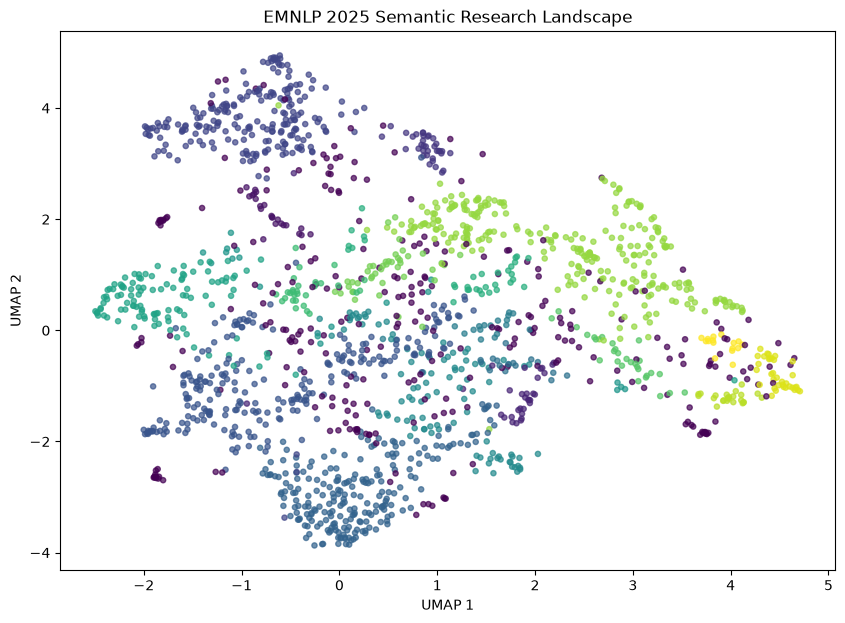

In [29]:
fig, ax = plt.subplots(figsize=(10, 7))

scatter = ax.scatter(
    df["umap_x"],
    df["umap_y"],
    c=df["cluster"],
    s=14,
    alpha=0.7
)

ax.set_title("EMNLP 2025 Semantic Research Landscape")
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")

plt.show()


## 8. Find representative papers for each cluster

Rather than sampling papers randomly, we identify papers closest to each cluster's semantic centroid.

These representative papers are useful for manually naming the research theme of each cluster.


In [30]:
def get_representative_papers(
    df,
    embeddings,
    cluster_id,
    n=5
):
    idx = df.index[df["cluster"] == cluster_id].to_numpy()

    if len(idx) == 0:
        return pd.DataFrame()

    cluster_embeddings = embeddings[idx]

    centroid = cluster_embeddings.mean(axis=0, keepdims=True)

    similarities = cosine_similarity(
        cluster_embeddings,
        centroid
    ).ravel()

    top_local_idx = np.argsort(similarities)[::-1][:n]
    top_global_idx = idx[top_local_idx]

    result = df.loc[
        top_global_idx,
        ["paper_id", "title", "abstract", "cluster"]
    ].copy()

    result["centroid_similarity"] = similarities[top_local_idx]

    return result


cluster_ids = sorted(
    cluster_id
    for cluster_id in df["cluster"].unique()
    if cluster_id != -1
)

for cluster_id in cluster_ids:
    print("\n" + "=" * 80)
    print(f"CLUSTER {cluster_id} — {sum(df['cluster'] == cluster_id)} papers")
    print("=" * 80)

    reps = get_representative_papers(
        df,
        embeddings,
        cluster_id,
        n=5
    )

    for _, row in reps.iterrows():
        print(f"- {row['title']}")



CLUSTER 0 — 23 papers
- The Illusion of Progress: Re-evaluating Hallucination Detection in LLM s
- SHARP : Steering Hallucination in LVLM s via Representation Engineering
- Mitigating Hallucinations in Vision-Language Models through Image-Guided Head Suppression
- Unconditional Truthfulness: Learning Unconditional Uncertainty of Large Language Models
- Unsupervised Hallucination Detection by Inspecting Reasoning Processes

CLUSTER 1 — 32 papers
- M ed- PRM : Medical Reasoning Models with Stepwise, Guideline-verified Process Rewards
- Process-Supervised Reward Models for Verifying Clinical Note Generation: A Scalable Approach Guided by Domain Expertise
- M ed F act: A Large-scale C hinese Dataset for Evidence-based Medical Fact-checking of LLM Responses
- M ed L ink DE – M ed DRA Entity Linking for G erman with Guided Chain of Thought Reasoning
- From Scores to Steps: Diagnosing and Improving LLM Performance in Evidence-Based Medical Calculations

CLUSTER 2 — 35 papers
- V ocal N et: S

## 9. Create a cluster-review table

This creates a compact table containing the top representative titles for every cluster.

Use this table to manually assign a human-readable topic label later.


In [31]:
cluster_review_rows = []

for cluster_id in cluster_ids:
    reps = get_representative_papers(
        df,
        embeddings,
        cluster_id,
        n=5
    )

    cluster_review_rows.append({
        "cluster": cluster_id,
        "n_papers": int((df["cluster"] == cluster_id).sum()),
        "representative_title_1": reps.iloc[0]["title"] if len(reps) > 0 else "",
        "representative_title_2": reps.iloc[1]["title"] if len(reps) > 1 else "",
        "representative_title_3": reps.iloc[2]["title"] if len(reps) > 2 else "",
        "representative_title_4": reps.iloc[3]["title"] if len(reps) > 3 else "",
        "representative_title_5": reps.iloc[4]["title"] if len(reps) > 4 else ""
    })

cluster_review = pd.DataFrame(cluster_review_rows)

cluster_review


,cluster,n_papers,representative_title_1,representative_title_2,representative_title_3,representative_title_4,representative_title_5
0,0,23,The Illusion of Progress: Re-evaluating Halluc...,SHARP : Steering Hallucination in LVLM s via R...,Mitigating Hallucinations in Vision-Language M...,Unconditional Truthfulness: Learning Unconditi...,Unsupervised Hallucination Detection by Inspec...
1,1,32,M ed- PRM : Medical Reasoning Models with Step...,Process-Supervised Reward Models for Verifying...,M ed F act: A Large-scale C hinese Dataset for...,M ed L ink DE – M ed DRA Entity Linking for G ...,From Scores to Steps: Diagnosing and Improving...
2,2,35,V ocal N et: Speech LLM s with Multi-Token Pre...,In-Context Learning Boosts Speech Recognition ...,From Tens of Hours to Tens of Thousands: Scali...,Koel- TTS : Enhancing LLM based Speech Generat...,MULTIVOX : A Benchmark for Evaluating Voice As...
3,3,216,U nified V isual: A Framework for Constructing...,C hart M ind: A Comprehensive Benchmark for Co...,SEA : Supervised Embedding Alignment for Token...,Enhancing Large Vision-Language Models with Ul...,QG - C o C : Question-Guided Chain-of-Captions...
4,4,242,MEB ench: Benchmarking Large Language Models f...,RPDR : A Round-trip Prediction-Based Data Augm...,Unstructured Evidence Attribution for Long Con...,T able RAG : A Retrieval Augmented Generation ...,Efficient Context Selection for Long-Context Q...
5,5,233,Step Guided Reasoning: Improving Mathematical ...,Do Large Language Models excel in Complex Logi...,PLAN - TUNING : Post-Training Language Models ...,FLARE : Faithful Logic-Aided Reasoning and Exp...,Mixing Inference-time Experts for Enhancing LL...
6,6,17,Self-Critique and Refinement for Faithful Natu...,A Causal Lens for Evaluating Faithfulness Metrics,Explaining Differences Between Model Pairs in ...,Towards Faithful Natural Language Explanations...,LLM s Don’t Know Their Own Decision Boundaries...
7,7,18,Co-Eval: Augmenting LLM -based Evaluation with...,Direct Judgement Preference Optimization,From Generation to Judgment: Opportunities and...,Improve LLM -as-a-Judge Ability as a General A...,C heck E val: A reliable LLM -as-a-Judge frame...
8,8,100,A Rigorous Evaluation of LLM Data Generation S...,Forget What You Know about LLM s Evaluations -...,Massive Supervised Fine-tuning Experiments Rev...,From Understanding to Generation: An Efficient...,CRITICTOOL : Evaluating Self-Critique Capabili...
9,9,19,Graceful Forgetting in Generative Language Models,RECALL : RE presentation-aligned Catastrophic-...,Mitigating Catastrophic Forgetting in Large La...,SEPS : A Separability Measure for Robust Unlea...,How to inject knowledge efficiently? Knowledge...


## 10. Save clustering outputs

Two files are produced:

- `emnlp_2025_clustered.csv` — every paper with its cluster and 2D UMAP coordinates
- `emnlp_2025_cluster_review.csv` — representative titles for manual cluster naming


In [32]:
CLUSTERED_FILE = Path("../data/processed/emnlp_2025_clustered.csv")
REVIEW_FILE = Path("../data/processed/emnlp_2025_cluster_review.csv")

df.to_csv(CLUSTERED_FILE, index=False)
cluster_review.to_csv(REVIEW_FILE, index=False)

print("Saved clustered corpus to:", CLUSTERED_FILE)
print("Saved cluster review table to:", REVIEW_FILE)


Saved clustered corpus to: ../data/processed/emnlp_2025_clustered.csv
Saved cluster review table to: ../data/processed/emnlp_2025_cluster_review.csv


## 11. Final clustering summary


In [33]:
print("=== TOPIC CLUSTERING SUMMARY ===")
print(f"Total papers: {len(df)}")
print(f"Clusters discovered: {n_clusters}")
print(f"Noise papers: {n_noise}")
print(f"Noise proportion: {n_noise / len(df):.1%}")

if n_clusters > 0:
    non_noise_counts = df.loc[df["cluster"] != -1, "cluster"].value_counts()
    print(f"Smallest cluster: {non_noise_counts.min()} papers")
    print(f"Largest cluster: {non_noise_counts.max()} papers")
    print(f"Median cluster size: {non_noise_counts.median():.0f} papers")


=== TOPIC CLUSTERING SUMMARY ===
Total papers: 1809
Clusters discovered: 19
Noise papers: 284
Noise proportion: 15.7%
Smallest cluster: 16 papers
Largest cluster: 271 papers
Median cluster size: 33 papers
